# Task 4 — Image Outpainting with Stable Diffusion

**Assignment 6 · Image Generation by Stable Diffusion.** This notebook implements **Task 4**:
extend an image beyond its original borders. Outpainting is **inpainting with the mask on the
newly-added canvas region** — same 9-channel checkpoint, mask inverted in spirit (the *border*
is generated, the original is kept).

### The "Important Question": what are `x` and `y` for outpainting?

- **`x` (condition) = the original image placed on a larger canvas + a border mask + a text prompt.**
- **`y` (target) = the extended image**: the original preserved in place, the new border
  synthesised to continue the scene.

Same conditioning structure as inpainting (9-channel UNet: latent + masked-image + mask); the
only difference from Task 3 is *where* the mask lives — the outer band instead of an interior
region. That is why both reuse the same model with no retraining.

## 0. Environment

In [1]:
%pip install -q "diffusers>=0.27" "transformers>=4.38" accelerate peft datasets safetensors ftfy "torchmetrics[image]" scipy matplotlib pandas pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and configuration

In [2]:
import os, gc, json, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw, ImageFilter
from tqdm.auto import tqdm

import torch
torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    inpaint_model_candidates: tuple = (
        "stable-diffusion-v1-5/stable-diffusion-inpainting",
        "botp/stable-diffusion-v1-5-inpainting",
    )
    resolution: int = 512
    img_dataset_candidates: tuple = (
        "sayakpaul/coco-30-val-2014", "zh-plus/tiny-imagenet", "nielsr/CelebA-faces",
    )
    use_local_images: bool = True       # use the assignment's "test images" folder
    local_images_dir: str = "test images"
    n_inputs: int = 10

    expand_ratio: float = 0.6    # fraction of the canvas the original occupies
    guidance_scale: float = 7.5
    num_inference_steps: int = 40
    seed: int = 42
    n_fid_images: int = 10
    quick_mode: bool = True

CFG = CFG()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"
if use_cuda and torch.cuda.is_bf16_supported(): weight_dtype = torch.bfloat16
elif use_cuda: weight_dtype = torch.float16
else: weight_dtype = torch.float32

OUT = Path("outputs_task4")
FIG, RES_DIR, GEN = OUT/"figures", OUT/"results", OUT/"generated"
for d in (FIG, RES_DIR, GEN): d.mkdir(parents=True, exist_ok=True)
print(f"device={device}  dtype={weight_dtype}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  dtype=torch.bfloat16
config: {
  "inpaint_model_candidates": [
    "stable-diffusion-v1-5/stable-diffusion-inpainting",
    "botp/stable-diffusion-v1-5-inpainting"
  ],
  "resolution": 512,
  "img_dataset_candidates": [
    "sayakpaul/coco-30-val-2014",
    "zh-plus/tiny-imagenet",
    "nielsr/CelebA-faces"
  ],
  "use_local_images": true,
  "local_images_dir": "test images",
  "n_inputs": 10,
  "expand_ratio": 0.6,
  "guidance_scale": 7.5,
  "num_inference_steps": 40,
  "seed": 42,
  "n_fid_images": 10,
  "quick_mode": true
}


## 2. The pipeline (report §2)

The same `StableDiffusionInpaintPipeline` (9-channel UNet) — outpainting needs no different
model, only a different mask.

In [3]:
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler

pipe=None
for name in CFG.inpaint_model_candidates:
    try:
        pipe=StableDiffusionInpaintPipeline.from_pretrained(
            name, torch_dtype=weight_dtype, safety_checker=None, requires_safety_checker=False)
        print("loaded inpaint model:", name); break
    except Exception as e:
        print(f"[skip] {name}: {type(e).__name__}: {str(e).splitlines()[0][:70]}")
assert pipe is not None, "no inpainting checkpoint could be loaded"
pipe.scheduler=DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True); pipe=pipe.to(device)

def count_params(m): return sum(p.numel() for p in m.parameters())
arch=pd.DataFrame([
    {"Component":"Text encoder (CLIP ViT-L/14)","Params (M)":round(count_params(pipe.text_encoder)/1e6,2)},
    {"Component":"VAE (AutoencoderKL)","Params (M)":round(count_params(pipe.vae)/1e6,2)},
    {"Component":f"UNet (inpaint, {pipe.unet.config.in_channels}-ch in)","Params (M)":round(count_params(pipe.unet)/1e6,2)},
])
arch.loc[len(arch)]=["TOTAL",round(arch["Params (M)"].sum(),2)]
arch.to_csv(RES_DIR/"architecture.csv",index=False); arch

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


An error occurred while trying to fetch C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


loaded inpaint model: stable-diffusion-v1-5/stable-diffusion-inpainting


,Component,Params (M)
0,Text encoder (CLIP ViT-L/14),123.06
1,VAE (AutoencoderKL),83.65
2,"UNet (inpaint, 9-ch in)",859.54
3,TOTAL,1066.25


## 3. Input images (report §3)

At least 10 real photos (COCO validation), centre-cropped to a square.

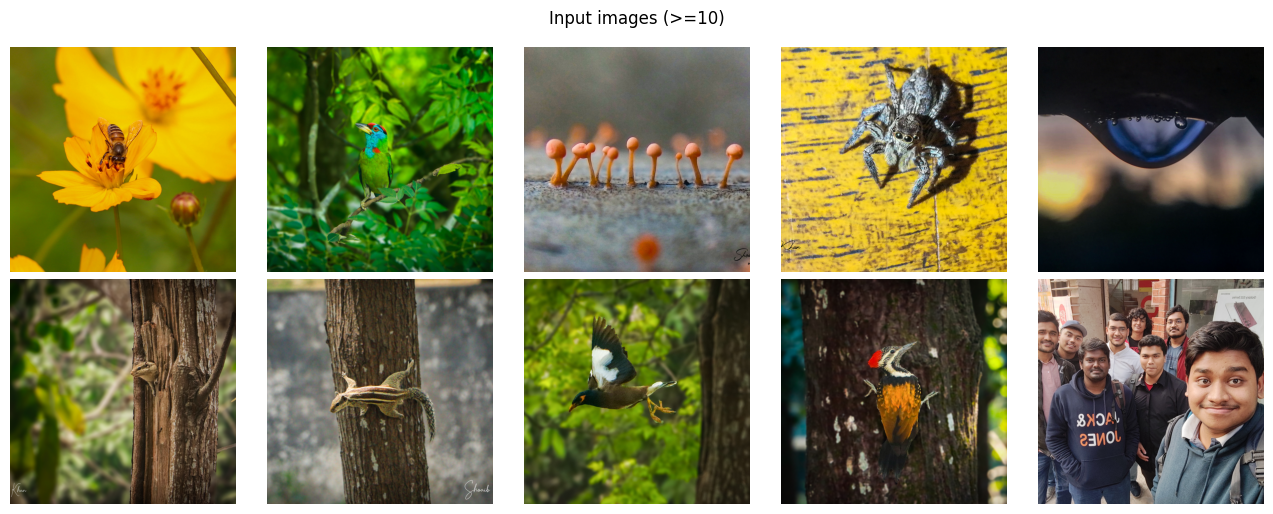

In [4]:
from datasets import load_dataset
from datasets.features import Image as HFImage

def prep_image(img):
    return ImageOps.fit(img.convert("RGB"), (CFG.resolution, CFG.resolution), Image.LANCZOS)

inputs=[]
if CFG.use_local_images and Path(CFG.local_images_dir).exists():
    paths=sorted([p for p in Path(CFG.local_images_dir).iterdir()
                  if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}])
    for p in paths[:CFG.n_inputs]:
        inputs.append({"image":prep_image(Image.open(p)),"caption":p.stem.replace("_"," ")})
else:
    ds=None
    for name in CFG.img_dataset_candidates:
        try: ds=load_dataset(name,split="train",streaming=True); src=name; break
        except Exception as e: print(f"[skip] {name}: {str(e).splitlines()[0][:60]}")
    assert ds is not None, "no image dataset could be loaded"
    feats=ds.features
    img_col=next((c for c,f in feats.items() if isinstance(f,HFImage)),"image")
    cap_col=next((c for c in ["caption","text","name"] if c in feats), None)
    for ex in ds:
        cap=ex.get(cap_col) if cap_col else None
        inputs.append({"image":prep_image(ex[img_col]),"caption":cap if isinstance(cap,str) else "a photo"})
        if len(inputs)>=CFG.n_inputs: break
    print(f"Loaded {len(inputs)} images from {src}")

def grid(images, titles=None, ncols=5, fs=2.6, suptitle=None, fname=None):
    n=len(images); ncols=min(ncols,n); nrows=math.ceil(n/ncols)
    fig,axes=plt.subplots(nrows,ncols,figsize=(fs*ncols,fs*nrows)); axes=np.array(axes).reshape(-1)
    for i,ax in enumerate(axes):
        if i<n:
            ax.imshow(images[i]); ax.axis("off")
            if titles: ax.set_title(titles[i], fontsize=8)
        else: ax.axis("off")
    if suptitle: fig.suptitle(suptitle)
    fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

grid([d["image"] for d in inputs], ncols=5, suptitle="Input images (>=10)", fname="t4_inputs.png")

## 4. Build the outpainting canvas and mask (report §4)

The original is shrunk and placed on a full-size canvas; the empty border is the region to
generate (white in the mask). The border is pre-filled with a blurred, upscaled copy of the
image so the VAE has plausible context to start from.

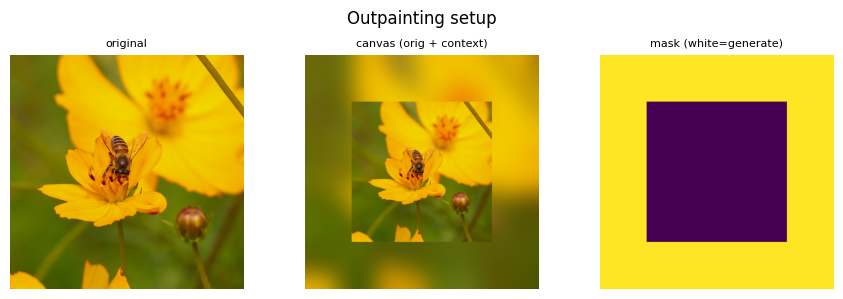

In [5]:
def make_outpaint(image, ratio=None, mode="all"):
    R=CFG.resolution; ratio=ratio if ratio is not None else CFG.expand_ratio
    ctx=image.resize((R,R), Image.LANCZOS).filter(ImageFilter.GaussianBlur(24))  # context fill
    canvas=ctx.copy(); mask=Image.new("L",(R,R),255); d=ImageDraw.Draw(mask)
    if mode=="all":
        w=h=int(R*ratio); x=y=(R-w)//2
    elif mode in ("right","left"):
        w=int(R*ratio); h=R; y=0; x=0 if mode=="right" else R-w
    else:
        raise ValueError(mode)
    orig=image.resize((w,h), Image.LANCZOS)
    canvas.paste(orig,(x,y))
    d.rectangle([x,y,x+w-1,y+h-1], fill=0)   # keep original region
    return canvas, mask, (x,y,w,h)

cv,mk,box=make_outpaint(inputs[0]["image"])
grid([inputs[0]["image"], cv, mk], titles=["original","canvas (orig + context)","mask (white=generate)"],
     ncols=3, fs=3.0, suptitle="Outpainting setup", fname="t4_setup.png")

## 5. Outpaint: extend the scene (report §7)

Each of the ≥10 images is extended all around; the prompt continues the scene (its caption).
We show original → extended.

outpaint:   0%|          | 0/10 [00:00<?, ?it/s]

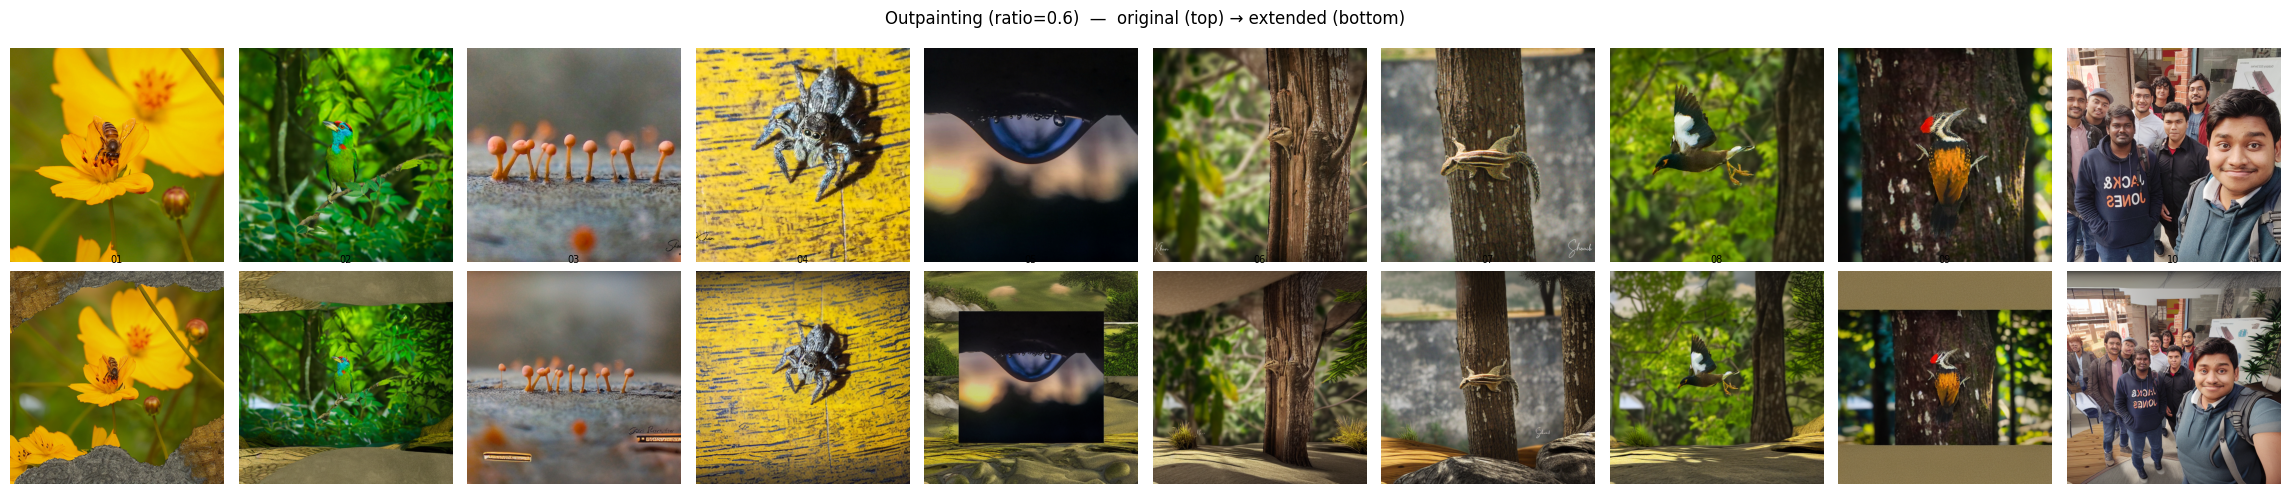

In [6]:
def outpaint(image, prompt, ratio=None, mode="all", guidance=None, steps=None, seed=0):
    canvas,mask,box=make_outpaint(image, ratio=ratio, mode=mode)
    g=torch.Generator(device=device).manual_seed(seed)
    out=pipe(prompt=prompt, image=canvas, mask_image=mask,
             guidance_scale=guidance if guidance is not None else CFG.guidance_scale,
             num_inference_steps=steps or CFG.num_inference_steps,
             height=CFG.resolution, width=CFG.resolution, generator=g).images[0]
    return out, box

for d in inputs:
    # use a real caption when available, else a generic scene prompt (test-folder names are numeric)
    cap=d["caption"] if len(str(d["caption"]).split()) >= 3 else "a photorealistic natural scene"
    d["prompt"]=f"{cap}, wide angle, extended scenery, seamless, high detail"

outputs=[]; boxes=[]
for d in tqdm(inputs, desc="outpaint"):
    o,box=outpaint(d["image"], d["prompt"], seed=CFG.seed); outputs.append(o); boxes.append(box)
    o.save(GEN/f"outpaint_{len(outputs)-1:02d}.png")

n=len(inputs)
fig,axes=plt.subplots(2,n,figsize=(2.3*n,5.0))
for i in range(n):
    axes[0,i].imshow(inputs[i]["image"]); axes[0,i].axis("off")
    axes[1,i].imshow(outputs[i]); axes[1,i].axis("off")
    axes[1,i].set_title(inputs[i]["caption"][:16], fontsize=7)
for r,t in enumerate(["original","extended"]): axes[r,0].set_ylabel(t, fontsize=10)
fig.suptitle(f"Outpainting (ratio={CFG.expand_ratio})  —  original (top) → extended (bottom)")
fig.tight_layout(); fig.savefig(FIG/"t4_outpaint_results.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Quantitative evaluation (report §8)

- **CLIP-text** — cosine(prompt, extended image): does the whole result match the prompt/scene?
- **Original-region PSNR/SSIM** — between the pasted original and the output over the kept
  (unmasked) box: is the original preserved and the seam continuous?
- **FID** — extended outputs vs input photos (indicative).

In [7]:
from torchmetrics.multimodal.clip_score import CLIPScore
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
from torchmetrics.functional import peak_signal_noise_ratio as psnr_fn
from torchmetrics.image.fid import FrechetInceptionDistance

def to_u8(img): return torch.from_numpy(np.array(img.convert("RGB"))).permute(2,0,1).contiguous()
def to_f(img):  return to_u8(img).float()/255.0
clip_metric=CLIPScore(model_name_or_path="openai/clip-vit-base-patch32").to(device)

@torch.no_grad()
def clip_text(img,prompt): return float(clip_metric(to_u8(img).to(device),prompt).cpu())

rows=[]
for i,(d,out,box) in enumerate(zip(inputs,outputs,boxes)):
    x,y,w,h=box
    kept_out=out.crop((x,y,x+w,y+h))
    kept_orig=d["image"].resize((w,h), Image.LANCZOS)
    a=to_f(kept_out).unsqueeze(0); b=to_f(kept_orig).unsqueeze(0)
    rows.append({"idx":i,"prompt":d["prompt"][:40],
                 "CLIP_text":round(clip_text(out,d["prompt"]),2),
                 "orig_PSNR":round(float(psnr_fn(a,b)),2),
                 "orig_SSIM":round(float(ssim_fn(a,b)),3)})
metrics_df=pd.DataFrame(rows); metrics_df.to_csv(RES_DIR/"per_image_metrics.csv",index=False)

fid=FrechetInceptionDistance(feature=2048, normalize=True).to(device)
def st(imgs): return torch.stack([to_f(im.resize((299,299))) for im in imgs]).to(device)
fid.update(st([d["image"] for d in inputs][:CFG.n_fid_images]), real=True)
fid.update(st(outputs[:CFG.n_fid_images]), real=False)

summary={"CLIP_text_mean":round(metrics_df["CLIP_text"].mean(),2),
         "orig_PSNR_mean":round(metrics_df["orig_PSNR"].mean(),2),
         "orig_SSIM_mean":round(metrics_df["orig_SSIM"].mean(),3),
         "FID_out_vs_input":round(float(fid.compute().cpu()),2),
         "n_inputs":len(inputs),"expand_ratio":CFG.expand_ratio}
json.dump(summary, open(RES_DIR/"summary_metrics.json","w"), indent=2)
print(json.dumps(summary, indent=2)); metrics_df

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{
  "CLIP_text_mean": 23.79,
  "orig_PSNR_mean": 36.7,
  "orig_SSIM_mean": 0.783,
  "FID_out_vs_input": 250.82,
  "n_inputs": 10,
  "expand_ratio": 0.6
}


,idx,prompt,CLIP_text,orig_PSNR,orig_SSIM
0,0,"a photorealistic natural scene, wide ang",23.94,39.77,0.878
1,1,"a photorealistic natural scene, wide ang",24.38,35.75,0.730
2,2,"a photorealistic natural scene, wide ang",20.76,38.47,0.819
3,3,"a photorealistic natural scene, wide ang",20.00,30.41,0.583
4,4,"a photorealistic natural scene, wide ang",25.74,44.60,0.933
5,5,"a photorealistic natural scene, wide ang",27.36,34.80,0.783
6,6,"a photorealistic natural scene, wide ang",24.76,35.29,0.753
7,7,"a photorealistic natural scene, wide ang",28.27,39.72,0.869
8,8,"a photorealistic natural scene, wide ang",23.10,36.40,0.777
9,9,"a photorealistic natural scene, wide ang",19.56,31.78,0.708


## 7. Experiments (report §10)

Vary the expansion ratio, the direction, the prompt, and generation parameters.

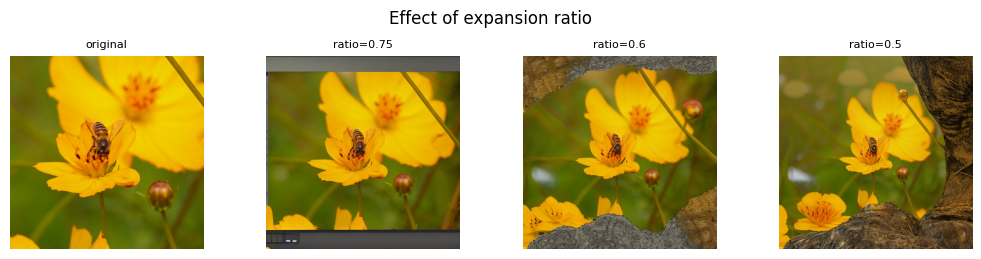

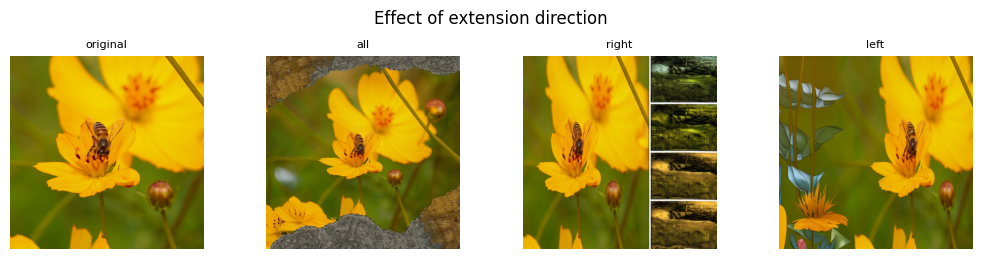

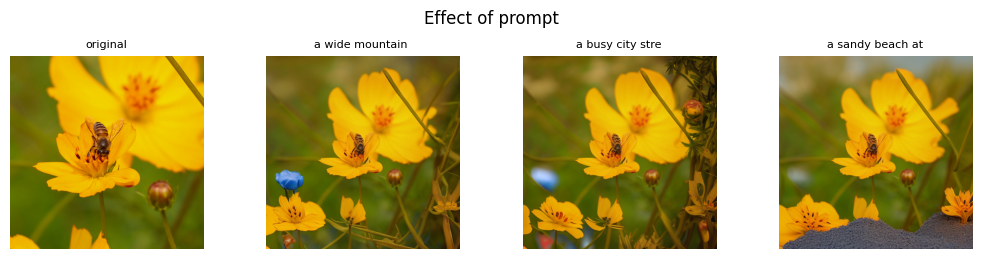

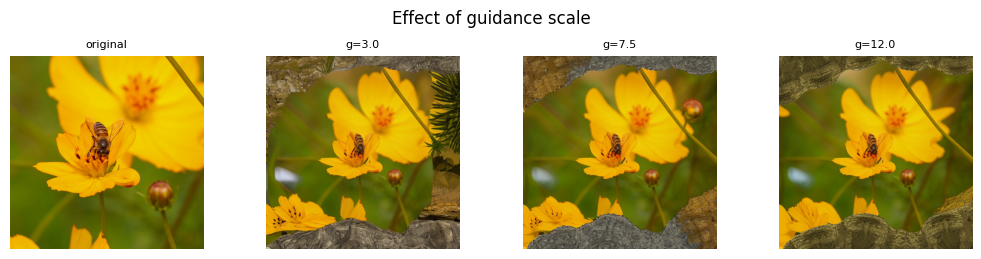

In [8]:
img0=inputs[0]["image"]; prm0=inputs[0]["prompt"]

# expansion ratio (smaller ratio => more area to generate)
imgs=[img0]; labels=["original"]
for r in [0.75,0.6,0.5]:
    o,_=outpaint(img0,prm0,ratio=r,seed=CFG.seed); imgs.append(o); labels.append(f"ratio={r}")
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of expansion ratio", fname="t4_ratio.png")

# direction
imgs=[img0]; labels=["original"]
for mode in ["all","right","left"]:
    o,_=outpaint(img0,prm0,mode=mode,seed=CFG.seed); imgs.append(o); labels.append(mode)
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of extension direction", fname="t4_direction.png")

# prompt variants
imgs=[img0]; labels=["original"]
for p in ["a wide mountain landscape with blue sky","a busy city street, wide shot",
          "a sandy beach at sunset, panorama"]:
    o,_=outpaint(img0,p,seed=CFG.seed); imgs.append(o); labels.append(p[:16])
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of prompt", fname="t4_prompt.png")

# guidance
imgs=[img0]; labels=["original"]
for gv in [3.0,7.5,12.0]:
    o,_=outpaint(img0,prm0,guidance=gv,seed=CFG.seed); imgs.append(o); labels.append(f"g={gv}")
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of guidance scale", fname="t4_guidance.png")

## 8. Discussion (report §11–§14)

**System.** Outpainting reuses the SD-1.5 inpainting model: the original is placed on a larger
canvas, the empty border is masked white, and the 9-channel UNet synthesises it under a prompt
while the original box (masked black) is preserved. No training.

**What the experiments show.** A smaller `expand_ratio` asks the model to invent more of the
scene — richer extension but more chance of drift and seams. Direction (all / left / right)
controls where new content grows. The prompt strongly steers the invented border (mountains vs
city vs beach), while the original stays fixed — the `orig_PSNR/SSIM` columns confirm the kept
region is preserved. Guidance trades prompt-adherence against artefacts as usual.

**Consistency.** The main challenge is a seamless boundary; the blurred-context fill plus a
prompt that continues the original scene (its caption) keeps the transition plausible. High
`orig_SSIM` shows the original is untouched; visual inspection is the real test of seam quality.

**Limitations.** Single seed; SD-1.5 was trained at 512², so large expansions can repeat texture
or lose global coherence; iterative/tiled outpainting would extend further with fewer artefacts.

**Bridge (the "Important Question").**

| Task | `x` | `y` | UNet input |
|---|---|---|---|
| Text-to-image | text | image | 4-ch |
| Image-to-image | text + input (noised init) | edited image | 4-ch |
| Inpainting | text + image + interior mask | filled image | 9-ch |
| **Outpainting (this task)** | **text + image-on-canvas + border mask** | extended image | **9-ch** |

Inpainting and outpainting share the exact conditioning structure and model — they differ only
in *where the mask is*. Figures/tables are under `outputs_task4/`.